# 01. EDA исходных отзывов — UCI Sentiment Labelled Sentences

**Цель исследования:** изучение структуры исходного корпуса, оценка качества
данных и формирование очищенной выборки для классификации тональности.
Анализ охватывает все три опубликованных источника: Amazon, Yelp и IMDb.
Целевая переменная: 0 — отрицательная, 1 — положительная тональность.

Источник: https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences
Лицензия: CC BY 4.0. Атрибуция: Kotzias, D. (2015), DOI 10.24432/C57604;
работа *From Group to Individual Labels Using Deep Features*, KDD 2015.


In [1]:
TASK = "text"

import hashlib
import json
import os
import platform
import random
import shutil
import sys
import tarfile
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    drive.mount("/content/drive")
    STORAGE = Path("/content/drive/MyDrive/data-enrichment-coursework")
    WORK = Path("/content/coursework_cache")
else:
    STORAGE = Path(os.environ.get("COURSEWORK_DATA_ROOT", ".local-data")).resolve()
    WORK = STORAGE / "cache"
RAW = STORAGE / "raw" / TASK
PROCESSED = STORAGE / "processed" / TASK
OUT = STORAGE / "results" / TASK
for folder in (RAW, PROCESSED, OUT, WORK):
    folder.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def download(url, target):
    target = Path(target)
    if target.exists() and target.stat().st_size:
        print("Используем сохранённый архив:", target.name)
        return target
    partial = target.with_suffix(target.suffix + ".part")
    for attempt in range(3):
        try:
            with requests.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                total = int(response.headers.get("content-length", 0))
                received = 0
                last_report = time.monotonic()
                with partial.open("wb") as handle:
                    for chunk in response.iter_content(1024 * 1024):
                        if not chunk:
                            continue
                        handle.write(chunk)
                        received += len(chunk)
                        if time.monotonic() - last_report > 15:
                            print(f"{target.name}: {received / 1e6:.1f} МБ / {total / 1e6:.1f} МБ")
                            last_report = time.monotonic()
                if total and received != total:
                    raise IOError("Неполная загрузка")
                partial.replace(target)
                print("Скачано:", target.name, target.stat().st_size, "байт")
                return target
        except (requests.RequestException, OSError):
            if attempt == 2:
                raise

def unpack(archive, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    fingerprint = sha256_file(archive)
    marker = destination / (Path(archive).name + ".sha256")
    if marker.exists() and marker.read_text() == fingerprint:
        return destination
    def output_path(name):
        path = (destination / name).resolve()
        if not path.is_relative_to(destination.resolve()):
            raise ValueError("Путь выходит за папку распаковки: " + name)
        return path
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as bundle:
            for member in bundle.infolist():
                path = output_path(member.filename)
                if member.is_dir():
                    path.mkdir(parents=True, exist_ok=True)
                else:
                    path.parent.mkdir(parents=True, exist_ok=True)
                    with bundle.open(member) as source, path.open("wb") as target:
                        shutil.copyfileobj(source, target)
    else:
        with tarfile.open(archive, "r:gz") as bundle:
            for member in bundle:
                path = output_path(member.name)
                if member.isdir():
                    path.mkdir(parents=True, exist_ok=True)
                elif member.isfile():
                    path.parent.mkdir(parents=True, exist_ok=True)
                    with bundle.extractfile(member) as source, path.open("wb") as target:
                        shutil.copyfileobj(source, target)
                # Ссылки и специальные файлы не распаковываются.
    marker.write_text(fingerprint)
    return destination

def save_json(name, data):
    (OUT / name).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

def provenance(sources, archives):
    save_json("provenance.json", {
        "executed_at_utc": datetime.now(timezone.utc).isoformat(),
        "seed": SEED, "sources": sources,
        "archives": [{"name": p.name, "bytes": p.stat().st_size,
                      "sha256": sha256_file(p)} for p in archives],
        "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                     "numpy": np.__version__, "matplotlib": matplotlib.__version__},
    })

def finish_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()


## 1. Загрузка полного опубликованного набора

Файлы Amazon, Yelp и IMDb читаются построчно, с разделением по **последней табуляции**.
Это сохраняет строки с кавычками, которые обычный CSV-парсер может ошибочно объединить.
Ошибочные строки записываются отдельно. Ожидаемый объём — 1 000 строк на источник.


In [2]:
URL = "https://archive.ics.uci.edu/static/public/331/sentiment%2Blabelled%2Bsentences.zip"
archive = download(URL, RAW / "sentiment_labelled_sentences.zip")
data_dir = unpack(archive, WORK / "uci_sentiment")
rows, parse_errors = [], []
for source, filename in [("amazon", "amazon_cells_labelled.txt"),
                         ("yelp", "yelp_labelled.txt"), ("imdb", "imdb_labelled.txt")]:
    matches = list(data_dir.rglob(filename))
    if len(matches) != 1:
        raise RuntimeError(f"Ожидался один {filename}, найдено {len(matches)}")
    # splitlines() treats U+0085 inside two IMDb reviews as a line break.
    # Records in this release are separated by LF, not by Unicode separators.
    lines = matches[0].read_text(encoding="utf-8-sig").split("\n")
    if lines and lines[-1] == "":
        lines.pop()
    for line_no, line in enumerate(lines, 1):
        try:
            text, label = line.rsplit("\t", 1)
            if label not in {"0", "1"}:
                raise ValueError("Метка не равна 0 или 1")
            rows.append({"id": f"{source}_{line_no:04d}", "text": text,
                         "label": int(label), "source": source, "line": line_no})
        except ValueError as error:
            parse_errors.append({"source": source, "line": line_no,
                                 "raw": line, "reason": str(error)})
original = pd.DataFrame(rows)
pd.DataFrame(parse_errors, columns=["source", "line", "raw", "reason"]).to_csv(
    OUT / "parse_errors.csv", index=False)
display(original.head())
display(original.groupby("source").agg(records=("id", "size")))
if len(original) != 3000 or parse_errors:
    raise RuntimeError("Структура исходного набора изменилась: смотрите parse_errors.csv")
assert original.groupby("source").size().eq(1000).all()
original.to_csv(PROCESSED / "reviews_original.csv", index=False)


,id,text,label,source,line
0,amazon_0001,So there is no way for me to plug it in here in the US unless I go by a converter.,0,amazon,1
1,amazon_0002,"Good case, Excellent value.",1,amazon,2
2,amazon_0003,Great for the jawbone.,1,amazon,3
3,amazon_0004,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,amazon,4
4,amazon_0005,The mic is great.,1,amazon,5


,records
source,
amazon,1000
imdb,1000
yelp,1000


Используем сохранённый архив: sentiment_labelled_sentences.zip


## 2. Пропуски, повторы и конфликтующие метки

Для поиска повторов тексты приводятся к нижнему регистру с нормализацией пробелов.
Пунктуация и исходный текст сохраняются. Метод выявляет точные нормализованные
повторы; семантическая близость текстов отдельно не оценивается.
Группы одинаковых текстов с разными метками отправляются в карантин целиком.
Для остальных групп повторов сохраняется первый ID. Исключения фиксируются отдельно.


In [3]:
original["normalized_text"] = original.text.str.lower().str.split().str.join(" ")
original["chars"] = original.text.str.len()
original["words"] = original.text.str.split().str.len()
empty = original.normalized_text.eq("")
conflict_keys = original.groupby("normalized_text").label.nunique()
conflict_keys = set(conflict_keys[conflict_keys > 1].index)
conflicts = original[original.normalized_text.isin(conflict_keys)].copy()
duplicates = original[original.duplicated("normalized_text", keep=False)].copy()
eligible = original[~empty & ~original.normalized_text.isin(conflict_keys)].copy()
clean = eligible.drop_duplicates("normalized_text", keep="first").copy()
removed = original[~original.id.isin(clean.id)].copy()
removed["reason"] = np.where(removed.normalized_text.eq(""), "empty_text",
    np.where(removed.normalized_text.isin(conflict_keys), "conflicting_labels", "duplicate"))
for name, table in [("reviews_clean.csv", clean), ("reviews_removed.csv", removed)]:
    table.to_csv(PROCESSED / name, index=False)
duplicates.to_csv(OUT / "duplicate_groups.csv", index=False)
conflicts.to_csv(OUT / "label_conflicts.csv", index=False)
summary = {"original_rows": len(original), "empty_texts": int(empty.sum()),
           "duplicate_group_rows": len(duplicates), "conflicting_rows": len(conflicts),
           "clean_rows": len(clean), "removed_rows": len(removed)}
save_json("summary.json", summary)
display(pd.Series(summary, name="value").to_frame())
display(removed[["id", "text", "label", "reason"]].head(10))


,value
original_rows,3000
empty_texts,0
duplicate_group_rows,40
conflicting_rows,0
clean_rows,2979
removed_rows,21


,id,text,label,reason
143,amazon_0144,very disappointed.,0,duplicate
285,amazon_0286,Great phone!.,1,duplicate
407,amazon_0408,Works great.,1,duplicate
524,amazon_0525,Works great!.,1,duplicate
543,amazon_0544,Don't buy this product.,0,duplicate
647,amazon_0648,Great phone.,1,duplicate
744,amazon_0745,"If you like a loud buzzing to override all your conversations, then this phone is for you!",0,duplicate
748,amazon_0749,Does not fit.,0,duplicate
768,amazon_0769,Great product.,1,duplicate
778,amazon_0779,This is a great deal.,1,duplicate


## 3. Баланс классов, источники и длина отзывов


label,negative,positive
source,,
amazon,496,491
imdb,498,498
yelp,497,499


words                                 ... chars                          
        count       mean       std  min  25%  ...   min   25%   50%    75%    max
source                                        ...                                
amazon  987.0  10.330294  6.675340  1.0  5.0  ...  11.0  27.0  48.0   78.0  149.0
imdb    996.0  14.403614  9.599086  1.0  7.0  ...   7.0  41.0  68.0  109.0  479.0
yelp    996.0  10.919679  6.259190  1.0  6.0  ...  11.0  33.0  51.0   80.0  149.0

[3 rows x 16 columns]

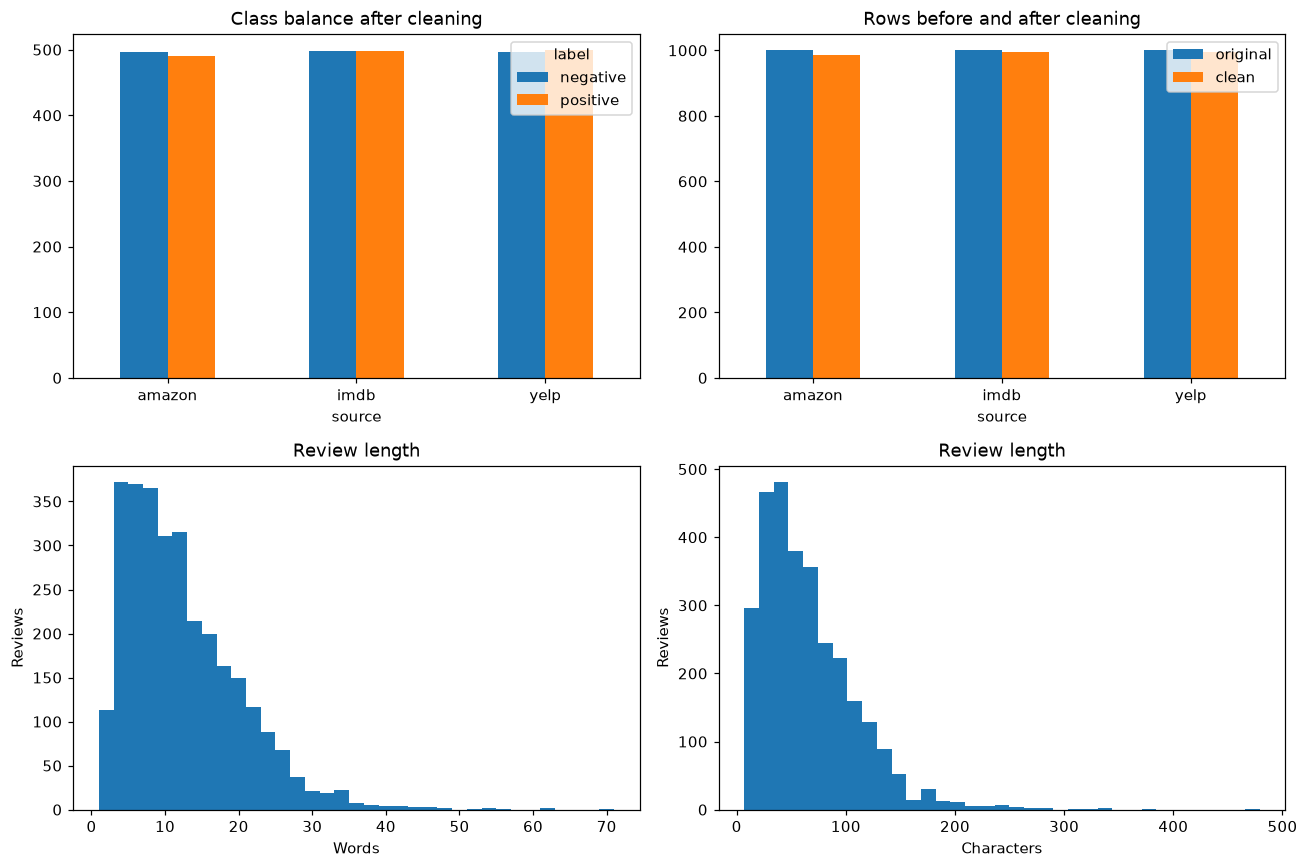

In [4]:
balance = pd.crosstab(clean.source, clean.label).reindex(columns=[0, 1], fill_value=0)
balance.to_csv(OUT / "class_balance.csv")
lengths = clean.groupby("source")[["words", "chars"]].describe()
lengths.to_csv(OUT / "text_lengths.csv")
display(balance.rename(columns={0: "negative", 1: "positive"}))
display(lengths)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
balance.rename(columns={0: "negative", 1: "positive"}).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set_title("Class balance after cleaning")
pd.DataFrame({"original": original.groupby("source").size(),
              "clean": clean.groupby("source").size()}).plot.bar(ax=axes[0, 1], rot=0)
axes[0, 1].set_title("Rows before and after cleaning")
axes[1, 0].hist(clean.words, bins=35)
axes[1, 0].set(xlabel="Words", ylabel="Reviews", title="Review length")
axes[1, 1].hist(clean.chars, bins=35)
axes[1, 1].set(xlabel="Characters", ylabel="Reviews", title="Review length")
finish_figure("text_eda.png")


## 4. Выводы

Сводные показатели исходного и очищенного наборов, распределение целевой
переменной и ограничения проведённого анализа.


In [5]:
report = (f"Исходный набор: {len(original)} строк, три источника.\n"
          f"После проверок: {len(clean)} строк. Исключено: {len(removed)}.\n"
          f"Пустых текстов: {int(empty.sum())}; строк с конфликтом меток: {len(conflicts)}.\n"
          f"Число отзывов по меткам: {clean.label.value_counts().sort_index().to_dict()}.\n"
          f"Медианная длина: {clean.words.median():.1f} слов.\n"
          "Ограничения: английский язык, три домена, только явно положительные и отрицательные оценки; "
          "проверка нормализованных повторов не исключает близкие по смыслу тексты.\n")
(OUT / "findings.txt").write_text(report, encoding="utf-8")
print(report)
provenance([{"url": URL, "page": "https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences",
             "license": "CC BY 4.0", "citation": "Kotzias (2015), DOI 10.24432/C57604"}], [archive])


Исходный набор: 3000 строк, три источника.
После проверок: 2979 строк. Исключено: 21.
Пустых текстов: 0; строк с конфликтом меток: 0.
Число отзывов по меткам: {0: 1491, 1: 1488}.
Медианная длина: 10.0 слов.
Ограничения: английский язык, три домена, только явно положительные и отрицательные оценки; проверка нормализованных повторов не исключает близкие по смыслу тексты.

